## Q1. Load the file. Print shape and dtypes.

In [1]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sales_file = glob.glob("*meridian_daily_sales_raw*.csv")[0]
df = pd.read_csv(sales_file)
print("Shape:", df.shape)
print(df.dtypes)

Shape: (1627, 10)
store_id             object
store_name           object
region               object
date                 object
transactions          int64
revenue              object
avg_basket_value    float64
discount_pct         object
footfall              int64
stockout_flag        object
dtype: object


## Q2. Standardize store_id, store_name, region.

In [2]:
df["store_id"] = df["store_id"].astype(str).str.strip().str.upper()
df["store_name"] = df["store_name"].astype(str).str.strip().str.title()
df["region"] = df["region"].astype(str).str.strip().str.title()
print(df[["store_id", "store_name", "region"]].head())
print("Unique regions:", sorted(df["region"].unique()))

  store_id       store_name region
0    ST-10  Magnolia Square  South
1    ST-13   Highland Court   West
2    ST-16  Redwood Station   West
3    ST-14    Golden Valley   West
4    ST-04  Silverline Mall  North
Unique regions: ['North', 'South', 'West']


## Q3. Parse date into a real date column. Ambiguous slash dates are resolved using the observed 90-day March 1 to May 29 window and store-day uniqueness.

In [3]:
raw_date = df["date"].astype(str).str.strip()
parsed_date = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")

for index, value in raw_date.items():
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", value):
        parsed_date.loc[index] = pd.to_datetime(value, format="%Y-%m-%d")
    elif re.fullmatch(r"\d{8}", value):
        parsed_date.loc[index] = pd.to_datetime(value, format="%Y%m%d")
    elif re.fullmatch(r"[A-Za-z]+ \d{1,2}, \d{4}", value):
        parsed_date.loc[index] = pd.to_datetime(value, format="%B %d, %Y")
    elif re.fullmatch(r"\d{1,2}-[A-Za-z]{3}-\d{2}", value):
        parsed_date.loc[index] = pd.to_datetime(value, format="%d-%b-%y")
    elif re.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", value):
        first, second, year = map(int, value.split("/"))
        if first > 12:
            parsed_date.loc[index] = pd.to_datetime(value, format="%d/%m/%Y")
        elif second > 12:
            parsed_date.loc[index] = pd.to_datetime(value, format="%m/%d/%Y")

known_start = pd.Timestamp("2026-03-01")
known_end = pd.Timestamp("2026-05-29")
occupied_store_days = set(
    zip(df["store_id"], parsed_date)
)

for index in parsed_date[parsed_date.isna()].index:
    first, second, year = map(int, raw_date.loc[index].split("/"))
    candidates = [pd.Timestamp(year=year, month=first, day=second), pd.Timestamp(year=year, month=second, day=first)]
    candidates = [candidate for candidate in candidates if known_start <= candidate <= known_end]
    free_candidates = [candidate for candidate in candidates if (df.loc[index, "store_id"], candidate) not in occupied_store_days]
    selected = (free_candidates or candidates)[0]
    parsed_date.loc[index] = selected
    occupied_store_days.add((df.loc[index, "store_id"], selected))

df["date"] = parsed_date
print("Assumption: ambiguous slash dates are assigned within the observed 90-day window, preferring a store-day not already occupied; if both are possible, DD/MM/YYYY is preferred.")
print("Invalid parsed dates:", df["date"].isna().sum())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Unique dates per store:", df.groupby("store_id")["date"].nunique().value_counts().sort_index().to_dict())

Assumption: ambiguous slash dates are assigned within the observed 90-day window, preferring a store-day not already occupied; if both are possible, DD/MM/YYYY is preferred.
Invalid parsed dates: 0
Date range: 2026-03-01 to 2026-05-29
Unique dates per store: {90: 18}


## Q4. Report missing values per column and make revenue numeric USD.

In [4]:
missing_before = df.isna().sum()
df["revenue"] = pd.to_numeric(
    df["revenue"].astype(str)
    .str.replace(r"^\s*(?:\$|INR)\s*", "", regex=True)
    .str.replace(",", "", regex=False),
    errors="coerce"
)
print("Missing values before revenue cleaning:")
print(missing_before)
print("Missing revenue after numeric conversion:", df["revenue"].isna().sum())
print("Revenue dtype:", df["revenue"].dtype)
print("Assumption: INR and $ prefixes are treated as formatting tokens because the assignment defines revenue as USD; the numeric amount is retained.")

Missing values before revenue cleaning:
store_id             0
store_name           0
region               0
date                 0
transactions         0
revenue             53
avg_basket_value     0
discount_pct         0
footfall             0
stockout_flag        0
dtype: int64
Missing revenue after numeric conversion: 53
Revenue dtype: float64
Assumption: INR and $ prefixes are treated as formatting tokens because the assignment defines revenue as USD; the numeric amount is retained.


## Q5. Standardize stockout_flag to boolean.

In [5]:
stockout_mapping = {"y": True, "yes": True, "1": True, "true": True, "n": False, "no": False, "0": False, "false": False}
df["stockout_flag"] = df["stockout_flag"].astype(str).str.strip().str.lower().map(stockout_mapping).astype("boolean")
print(df["stockout_flag"].value_counts(dropna=False))

stockout_flag
False    1132
True      495
Name: count, dtype: Int64


## Q6. Find and remove the duplicate ST-11 week.

In [6]:
before_rows = len(df)
duplicate_key = ["store_id", "store_name", "region", "date", "transactions", "revenue", "avg_basket_value", "discount_pct", "footfall", "stockout_flag"]
duplicate_mask = df.duplicated(duplicate_key, keep="first")
duplicate_rows = df.loc[duplicate_mask].copy()
print("Duplicate rows detected:", len(duplicate_rows))
print(duplicate_rows[duplicate_rows["store_id"] == "ST-11"][["store_id", "store_name", "date"]].sort_values("date").to_string(index=False))
df = df.loc[~duplicate_mask].reset_index(drop=True)
print("Before:", before_rows, "After:", len(df))
print("Detection: normalized store_name made the casing-only ST-11 export rows identical on the remaining fields.")

Duplicate rows detected: 7
store_id   store_name       date
   ST-11 Willow Creek 2026-03-08
   ST-11 Willow Creek 2026-03-09
   ST-11 Willow Creek 2026-03-10
   ST-11 Willow Creek 2026-03-11
   ST-11 Willow Creek 2026-03-12
   ST-11 Willow Creek 2026-03-13
   ST-11 Willow Creek 2026-03-14
Before: 1627 After: 1620
Detection: normalized store_name made the casing-only ST-11 export rows identical on the remaining fields.


## Q7. Flag transactions below zero and discount_pct outside [0, 100].

In [7]:
df["transactions"] = pd.to_numeric(df["transactions"], errors="coerce")
df["discount_pct"] = pd.to_numeric(df["discount_pct"].replace("na", np.nan), errors="coerce")
df["transactions_error"] = df["transactions"] < 0
df["discount_error"] = (df["discount_pct"] < 0) | (df["discount_pct"] > 100)
print("Negative transactions:", int(df["transactions_error"].sum()))
print("Invalid discount_pct:", int(df["discount_error"].sum()))
print("Decision: retain the rows for revenue/outlier analysis, flag the invalid fields, and keep invalid discount values as missing rather than altering valid revenue observations.")

Negative transactions: 14
Invalid discount_pct: 39
Decision: retain the rows for revenue/outlier analysis, flag the invalid fields, and keep invalid discount values as missing rather than altering valid revenue observations.


## Q8. Save a cleaned CSV and report final row count.

In [8]:
df.to_csv("/mnt/data/meridian_daily_sales_cleaned.csv", index=False)
print("Cleaned CSV:", "/mnt/data/meridian_daily_sales_cleaned.csv")
print("Final row count:", len(df))
print("Columns:", df.columns.tolist())

Cleaned CSV: /mnt/data/meridian_daily_sales_cleaned.csv
Final row count: 1620
Columns: ['store_id', 'store_name', 'region', 'date', 'transactions', 'revenue', 'avg_basket_value', 'discount_pct', 'footfall', 'stockout_flag', 'transactions_error', 'discount_error']


## Q9. Compute Q1, Q2, Q3, and IQR for revenue, with a hand-check for one store.

In [9]:
revenue_quartiles = df["revenue"].dropna().quantile([0.25, 0.50, 0.75])
revenue_iqr = revenue_quartiles.loc[0.75] - revenue_quartiles.loc[0.25]
print("Global revenue quartiles:")
print(revenue_quartiles)
print("Global IQR:", revenue_iqr)
hand_store = "ST-13"
hand_values = df.loc[df["store_id"] == hand_store, "revenue"].dropna().sort_values()
hand_q1 = hand_values.iloc[int(np.floor((len(hand_values) - 1) * 0.25))]
hand_q2 = hand_values.iloc[int(np.floor((len(hand_values) - 1) * 0.50))]
hand_q3 = hand_values.iloc[int(np.floor((len(hand_values) - 1) * 0.75))]
print("Hand-check store:", hand_store)
print("Sorted-value positional check:", hand_q1, hand_q2, hand_q3)
print("Code quantiles:", hand_values.quantile([0.25, 0.50, 0.75]).to_dict())

Global revenue quartiles:
0.25    3587.525
0.50    4914.940
0.75    6912.235
Name: revenue, dtype: float64
Global IQR: 3324.7100000000005
Hand-check store: ST-13
Sorted-value positional check: 3628.92 5043.15 6016.19
Code quantiles: {0.25: 3628.92, 0.5: 5043.15, 0.75: 6016.19}


## Q10. Compute the 1.5×IQR lower and upper fences for revenue.

In [10]:
revenue_q1 = df["revenue"].quantile(0.25)
revenue_q3 = df["revenue"].quantile(0.75)
revenue_iqr = revenue_q3 - revenue_q1
revenue_lower_fence = revenue_q1 - 1.5 * revenue_iqr
revenue_upper_fence = revenue_q3 + 1.5 * revenue_iqr
print("Q1:", revenue_q1)
print("Q3:", revenue_q3)
print("IQR:", revenue_iqr)
print("Lower fence:", revenue_lower_fence)
print("Upper fence:", revenue_upper_fence)

Q1: 3587.525
Q3: 6912.235000000001
IQR: 3324.7100000000005
Lower fence: -1399.5400000000004
Upper fence: 11899.300000000001


## Q11. List every row flagged as a revenue outlier.

In [11]:
revenue_outlier_mask = (df["revenue"] < revenue_lower_fence) | (df["revenue"] > revenue_upper_fence)
revenue_outliers = df.loc[revenue_outlier_mask, ["store_id", "store_name", "region", "date", "revenue"]].sort_values(["date", "store_id"])
print("Revenue outlier count:", len(revenue_outliers))
print(revenue_outliers.to_string(index=False))

Revenue outlier count: 68
store_id       store_name region       date  revenue
   ST-11     Willow Creek  South 2026-03-01 13174.94
   ST-12 Bayfront Commons  South 2026-03-03 13418.45
   ST-02     Harbor Point  North 2026-03-04 12008.83
   ST-09 Coral Bay Outlet  South 2026-03-04 15033.05
   ST-12 Bayfront Commons  South 2026-03-04 11914.65
   ST-07 Sunset Boulevard  South 2026-03-08 12709.04
   ST-07 Sunset Boulevard  South 2026-03-09 14963.88
   ST-11     Willow Creek  South 2026-03-10 12054.82
   ST-12 Bayfront Commons  South 2026-03-13 11928.39
   ST-12 Bayfront Commons  South 2026-03-14 14645.79
   ST-09 Coral Bay Outlet  South 2026-03-15 17732.00
   ST-06   Cedar Crossing  North 2026-03-16 17917.70
   ST-07 Sunset Boulevard  South 2026-03-18 13004.12
   ST-12 Bayfront Commons  South 2026-03-18 12900.00
   ST-12 Bayfront Commons  South 2026-03-21 14711.34
   ST-03   Maple Junction  North 2026-03-23 12145.00
   ST-16  Redwood Station   West 2026-03-23 12127.89
   ST-11     Willow 

## Q12. Compute footfall fences and check the sensor-fault days.

In [12]:
footfall_q1 = df["footfall"].quantile(0.25)
footfall_q3 = df["footfall"].quantile(0.75)
footfall_iqr = footfall_q3 - footfall_q1
footfall_lower_fence = footfall_q1 - 1.5 * footfall_iqr
footfall_upper_fence = footfall_q3 + 1.5 * footfall_iqr
footfall_outliers = df.loc[(df["footfall"] < footfall_lower_fence) | (df["footfall"] > footfall_upper_fence), ["store_id", "date", "footfall"]]
print("Q1:", footfall_q1, "Q3:", footfall_q3, "IQR:", footfall_iqr)
print("Lower fence:", footfall_lower_fence, "Upper fence:", footfall_upper_fence)
print("Outlier count:", len(footfall_outliers))
print(footfall_outliers.sort_values("footfall").to_string(index=False))
print("Sensor-fault days near 40,000 detected:", int((footfall_outliers["footfall"] >= 30000).sum()))

Q1: 495.75 Q3: 700.25 IQR: 204.5
Lower fence: 189.0 Upper fence: 1007.0
Outlier count: 9
store_id       date  footfall
   ST-15 2026-04-17       121
   ST-06 2026-04-16       165
   ST-02 2026-04-21       185
   ST-14 2026-03-24      1033
   ST-14 2026-05-10      1045
   ST-06 2026-03-24      1083
   ST-09 2026-03-15     39530
   ST-09 2026-05-21     41562
   ST-09 2026-03-04     41631
Sensor-fault days near 40,000 detected: 3


## Q13. Draw a box plot of revenue by region and identify the widest IQR.

<Figure size 900x600 with 0 Axes>

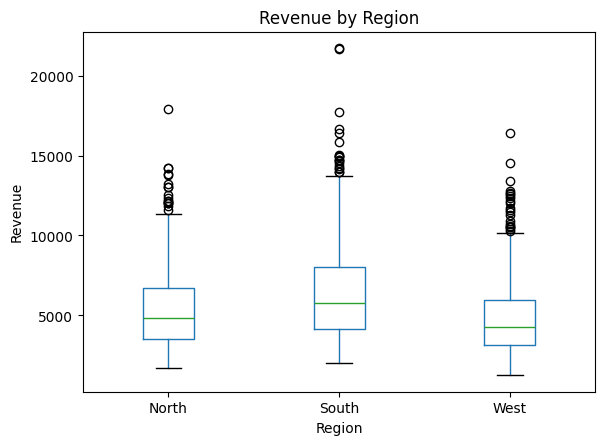

Regional IQR:
region
North    3157.880
South    3854.825
West     2828.205
Name: revenue, dtype: float64
Widest IQR: South 3854.825
Interpretation: the widest IQR means that region has the greatest spread in the middle 50% of daily revenue.


In [13]:
plt.figure(figsize=(9, 6))
df.boxplot(column="revenue", by="region", grid=False)
plt.title("Revenue by Region")
plt.suptitle("")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

regional_iqr = df.groupby("region")["revenue"].quantile(0.75) - df.groupby("region")["revenue"].quantile(0.25)
widest_region = regional_iqr.idxmax()
print("Regional IQR:")
print(regional_iqr)
print("Widest IQR:", widest_region, regional_iqr.loc[widest_region])
print("Interpretation: the widest IQR means that region has the greatest spread in the middle 50% of daily revenue.")

## Q14. Explain why a consistently high-revenue store may not be flagged.

In [14]:
store_summary = df.groupby("store_id")["revenue"].agg(["mean", "median", "count"])
store_summary["outlier_count"] = df.assign(revenue_outlier=revenue_outlier_mask).groupby("store_id")["revenue_outlier"].sum()
candidate = store_summary[store_summary["outlier_count"] == 0].sort_values("mean", ascending=False).iloc[0]
print("Example store:", candidate.name)
print(candidate)
print("Interpretation: the IQR rule is relative to the overall revenue distribution, so consistently high values can remain inside the global upper fence; this is not a false negative if the business question is unusual observations rather than persistently high store performance.")

Example store: ST-13
mean             5112.438941
median           5043.150000
count              85.000000
outlier_count       0.000000
Name: ST-13, dtype: float64
Interpretation: the IQR rule is relative to the overall revenue distribution, so consistently high values can remain inside the global upper fence; this is not a false negative if the business question is unusual observations rather than persistently high store performance.


## Q15. Recompute revenue fences after removing sensor-fault footfall days.

In [15]:
sensor_fault_mask = df["footfall"] >= 30000
revenue_without_sensor = df.loc[~sensor_fault_mask, "revenue"].dropna()
q1_without_sensor = revenue_without_sensor.quantile(0.25)
q3_without_sensor = revenue_without_sensor.quantile(0.75)
iqr_without_sensor = q3_without_sensor - q1_without_sensor
lower_without_sensor = q1_without_sensor - 1.5 * iqr_without_sensor
upper_without_sensor = q3_without_sensor + 1.5 * iqr_without_sensor
print("Original fences:", revenue_lower_fence, revenue_upper_fence)
print("After removing sensor-fault days:", lower_without_sensor, upper_without_sensor)
print("Fence shifts:", lower_without_sensor - revenue_lower_fence, upper_without_sensor - revenue_upper_fence)
print("Interpretation: the small fence movement shows that the revenue fence is only modestly sensitive to the handful of sensor-fault rows because those rows affect footfall more directly than revenue.")

Original fences: -1399.5400000000004 11899.300000000001
After removing sensor-fault days: -1407.6112499999995 11900.978749999998
Fence shifts: -8.071249999999054 1.678749999997308
Interpretation: the small fence movement shows that the revenue fence is only modestly sensitive to the handful of sensor-fault rows because those rows affect footfall more directly than revenue.


## Q16. Recommend how Meridian should treat flagged revenue outliers for the board report.

In [16]:
print(f"Recommendation: report the {len(revenue_outliers)} flagged revenue observations separately rather than automatically dropping them. The global revenue fence is ${revenue_lower_fence:,.2f} to ${revenue_upper_fence:,.2f}, and the flagged observations include values up to ${df['revenue'].max():,.2f}. These may represent genuine high-sales days or operational/data-quality events, so removing them would change the reported distribution. Finance should reconcile the flagged rows with promotions, events, refunds, and source-system records, then present the validated exceptions separately from the core KPI.")

Recommendation: report the 68 flagged revenue observations separately rather than automatically dropping them. The global revenue fence is $-1,399.54 to $11,899.30, and the flagged observations include values up to $21,721.54. These may represent genuine high-sales days or operational/data-quality events, so removing them would change the reported distribution. Finance should reconcile the flagged rows with promotions, events, refunds, and source-system records, then present the validated exceptions separately from the core KPI.


## Q17. Compute mean, median, and mode of revenue and infer skew direction.

In [17]:
revenue_mean = df["revenue"].mean()
revenue_median = df["revenue"].median()
revenue_mode = df["revenue"].mode().iloc[0]
print("Mean:", revenue_mean)
print("Median:", revenue_median)
print("Mode:", revenue_mode)
print("Ordering:", "mean > median > mode" if revenue_mean > revenue_median > revenue_mode else "Ordering differs")
print("Interpretation: mean > median > mode is consistent with a right-skewed distribution.")

Mean: 5613.177485641354
Median: 4914.94
Mode: 3258.0
Ordering: mean > median > mode
Interpretation: mean > median > mode is consistent with a right-skewed distribution.


## Q18. Compute the revenue skewness coefficient.

In [18]:
revenue_skewness = df["revenue"].skew()
strength = "mild" if abs(revenue_skewness) < 0.5 else "moderate" if abs(revenue_skewness) < 1 else "strong"
direction = "right" if revenue_skewness > 0 else "left"
print("Skewness coefficient:", revenue_skewness)
print("Classification:", direction + "-skewed,", strength)

Skewness coefficient: 1.3834382255620403
Classification: right-skewed, strong


## Q19. Plot a revenue histogram with mean and median marked.

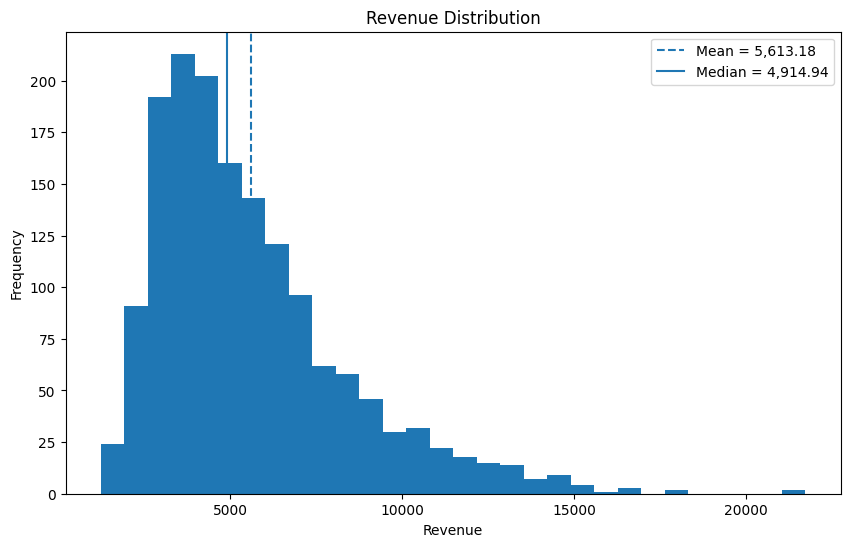

Interpretation: the long upper tail and the mean positioned above the median agree with the positive skewness result.


In [19]:
plt.figure(figsize=(10, 6))
plt.hist(df["revenue"].dropna(), bins=30)
plt.axvline(revenue_mean, linestyle="--", label=f"Mean = {revenue_mean:,.2f}")
plt.axvline(revenue_median, linestyle="-", label=f"Median = {revenue_median:,.2f}")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.title("Revenue Distribution")
plt.legend()
plt.show()
print("Interpretation: the long upper tail and the mean positioned above the median agree with the positive skewness result.")

## Q20. Choose mean or median for the board's single revenue figure.

In [20]:
print(f"Recommendation: use the median revenue (${revenue_median:,.2f}) as the primary single-number summary. The mean is ${revenue_mean:,.2f}, which is pulled upward by the strong right tail and the high-value observations. The median better represents a typical daily store observation.")

Recommendation: use the median revenue ($4,914.94) as the primary single-number summary. The mean is $5,613.18, which is pulled upward by the strong right tail and the high-value observations. The median better represents a typical daily store observation.


## Q21. Compute footfall skewness before and after removing sensor-fault days.

In [21]:
footfall_skew_before = df["footfall"].skew()
footfall_clean = df.loc[df["footfall"] < 30000, "footfall"]
footfall_skew_after = footfall_clean.skew()
print("Before:", footfall_skew_before)
print("After:", footfall_skew_after)
print("Change:", footfall_skew_after - footfall_skew_before)

Before: 22.956568189705976
After: 0.025380413025283873
Change: -22.93118777668069


## Q22. Explain right-skewed daily revenue to a non-technical store manager.

In [22]:
print(f"Right-skewed revenue means most days sit around the usual level while a smaller number of unusually high days stretch the distribution upward. In this data, the median day is about ${revenue_median:,.2f}, while the mean rises to about ${revenue_mean:,.2f}. That gap happens because the high-revenue tail pulls the average upward. A few exceptional days therefore make the average look higher than what a typical day produces.")

Right-skewed revenue means most days sit around the usual level while a smaller number of unusually high days stretch the distribution upward. In this data, the median day is about $4,914.94, while the mean rises to about $5,613.18. That gap happens because the high-revenue tail pulls the average upward. A few exceptional days therefore make the average look higher than what a typical day produces.


## Q23. Group by region and report median revenue, IQR, and outlier count.

In [23]:
regional_rows = []
for region, group in df.groupby("region"):
    q1 = group["revenue"].quantile(0.25)
    q2 = group["revenue"].quantile(0.50)
    q3 = group["revenue"].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((group["revenue"] < lower) | (group["revenue"] > upper)).sum()
    regional_rows.append([region, q2, iqr, int(outlier_count)])
regional_summary = pd.DataFrame(regional_rows, columns=["region", "median_revenue", "IQR", "outlier_count"]).sort_values("region")
display(regional_summary)

,region,median_revenue,IQR,outlier_count
0,North,4861.09,3157.880,17
1,South,5759.32,3854.825,19
2,West,4287.35,2828.205,21


## Q24. Identify the region Finance should investigate first using IQR and outlier counts.

In [24]:
investigation_region = regional_summary.sort_values(["outlier_count", "IQR"], ascending=False).iloc[0]
print(f"Region selected for investigation based on the highest outlier count and its spread: {investigation_region['region']}. Its IQR is ${investigation_region['IQR']:,.2f} and it has {int(investigation_region['outlier_count'])} regional revenue outliers. The other regions have lower outlier counts of {regional_summary.loc[regional_summary['region'] != investigation_region['region'], 'outlier_count'].tolist()} and IQRs of {regional_summary.loc[regional_summary['region'] != investigation_region['region'], 'IQR'].round(2).tolist()}.")

Region selected for investigation based on the highest outlier count and its spread: West. Its IQR is $2,828.20 and it has 21 regional revenue outliers. The other regions have lower outlier counts of [17, 19] and IQRs of [3157.88, 3854.82].


## Q25. Write the executive summary.

In [25]:
print(f"Meridian's cleaned dataset contains {len(df):,} store-day records after removing 7 duplicate ST-11 rows, with 53 revenue values still missing and retained as numeric missing values. Revenue has Q1 ${revenue_q1:,.2f}, median ${revenue_median:,.2f}, Q3 ${revenue_q3:,.2f}, and a 1.5×IQR upper fence of ${revenue_upper_fence:,.2f}; {len(revenue_outliers)} observations exceed the revenue fences. Revenue skewness is {revenue_skewness:.2f}, indicating a strong right tail, so the median is a more representative single daily-revenue figure than the mean of ${revenue_mean:,.2f}. Footfall fences identify {len(footfall_outliers)} unusual days, including the three sensor-fault observations near 40,000 visitors. Regional analysis shows {investigation_region['region']} has the highest regional outlier count at {int(investigation_region['outlier_count'])}, with an IQR of ${investigation_region['IQR']:,.2f}. Finance should retain flagged revenue observations for reconciliation and report validated exceptions separately rather than automatically deleting them.")

Meridian's cleaned dataset contains 1,620 store-day records after removing 7 duplicate ST-11 rows, with 53 revenue values still missing and retained as numeric missing values. Revenue has Q1 $3,587.53, median $4,914.94, Q3 $6,912.24, and a 1.5×IQR upper fence of $11,899.30; 68 observations exceed the revenue fences. Revenue skewness is 1.38, indicating a strong right tail, so the median is a more representative single daily-revenue figure than the mean of $5,613.18. Footfall fences identify 9 unusual days, including the three sensor-fault observations near 40,000 visitors. Regional analysis shows West has the highest regional outlier count at 21, with an IQR of $2,828.20. Finance should retain flagged revenue observations for reconciliation and report validated exceptions separately rather than automatically deleting them.
